# **Histogram 기본기 익히기**

matplotlib의 히스토그램을 학습하기 위한 실습입니다.


## **한글 폰트 설치**

In [1]:
# !pip install -q koreanize-matplotlib
# import koreanize_matplotlib
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# plt.rcParams['axes.unicode_minus'] = False
# %matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# 운영체제에 맞춰 한글 폰트 지정 (Visual Studio 환경이면 'nt'인 Windows로 작동)
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'

# 축의 음수(-) 기호가 깨지는 현상 방지x
plt.rcParams['axes.unicode_minus'] = False

## **히스토그램 기본 명령어**

| 명령어 / 옵션 | 의미 |
|---|---|
| `plt.hist(데이터)` | 데이터의 히스토그램 그리기 |
| `edgecolor='색상'` | 막대의 테두리 색 |
| `bins=n` | 구간(막대)의 개수 (기본값은 데이터의 고유값 개수만큼) |
| `range=(최소, 최대)` | 히스토그램에서 보여줄 값의 범위 |
| `alpha=값` | 투명도 — 여러 히스토그램을 겹쳐 그릴 때 유용 |


## **데이터 불러오기**

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_scores.csv")
df.head()

,이름,공부시간,점수,출석률,성별
0,학생1,7,83,78,여
1,학생2,4,68,70,여
2,학생3,8,87,96,여
3,학생4,5,70,68,여
4,학생5,7,78,89,남


### **Q1. 기본 히스토그램 그리기**

학생 40명의 점수 분포를 가장 기본적인 형태의 히스토그램으로 그려보자.


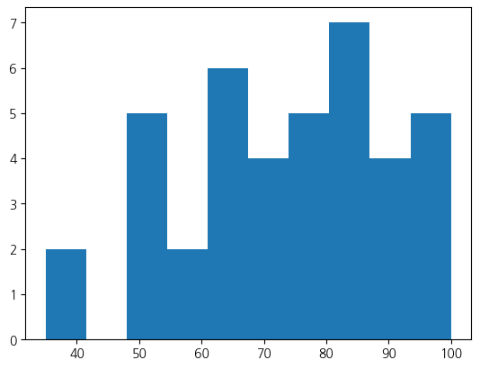

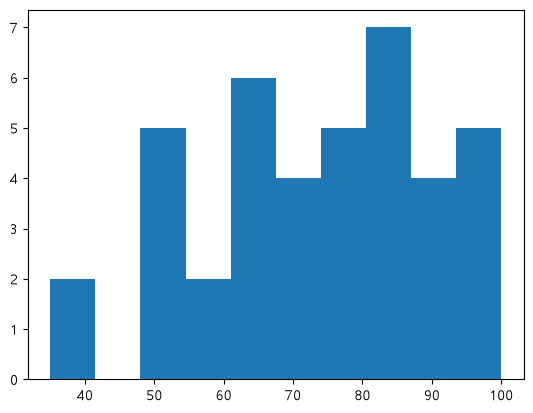

In [12]:
# code here
plt.hist(df["점수"])
plt.show()

### **Q2. 제목과 축 이름 붙이기**

- 제목 : '학생 점수 분포'
- X축 이름 : '점수'
- Y축 이름 : '학생 수'


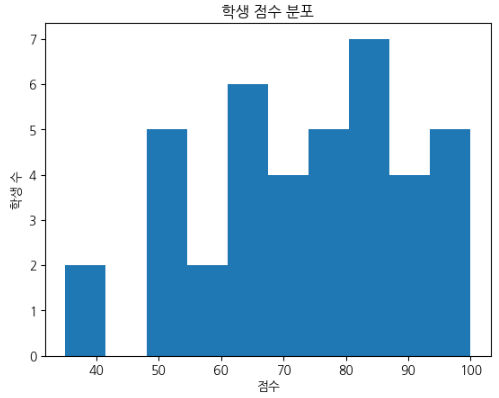

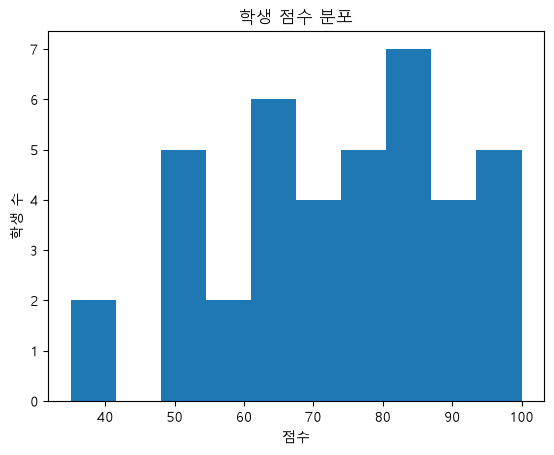

In [11]:
# code here
plt.title("학생 점수 분포")
plt.xlabel("점수")
plt.ylabel("학생 수")
plt.hist(df["점수"])
plt.show()

### **Q3. 막대 테두리 넣기**

- 막대마다 검은 테두리를 넣어 그려보자.

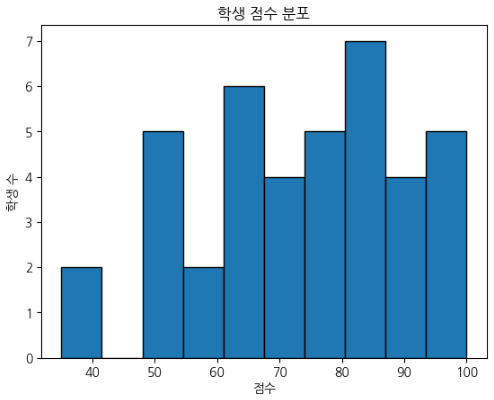

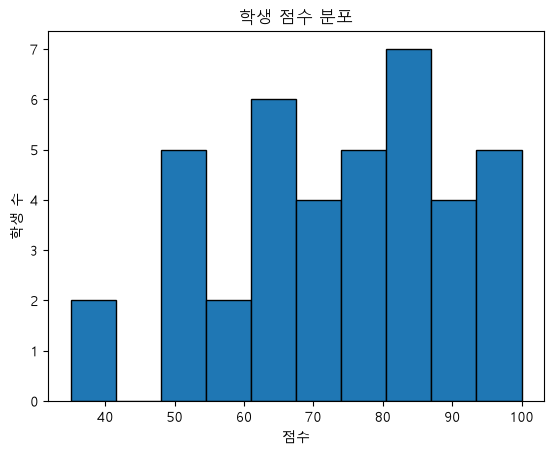

In [10]:
# code here
plt.title("학생 점수 분포")
plt.xlabel("점수")
plt.ylabel("학생 수")
plt.hist(df["점수"], edgecolor = "black")
plt.show()

### **Q4. 구간 개수 지정하기**

구간을 20개로 나눠 더 세밀한 히스토그램을 그려보자.


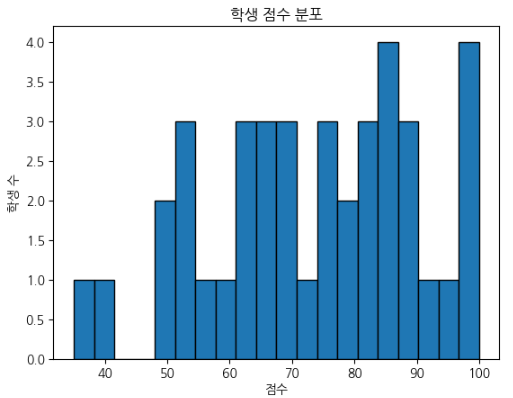

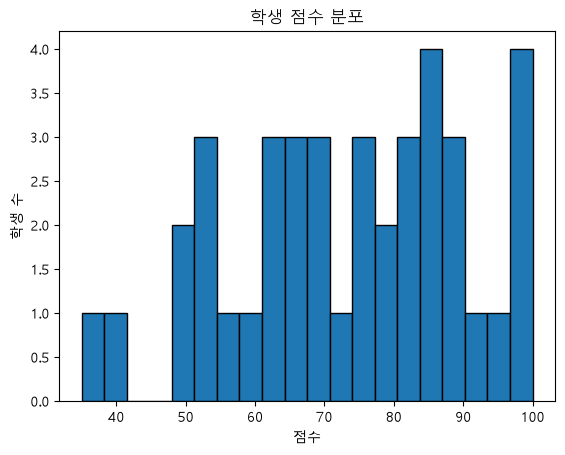

In [8]:
# code here
plt.title("학생 점수 분포")
plt.xlabel("점수")
plt.ylabel("학생 수")
plt.hist(df["점수"], edgecolor = "black", bins = 20)
plt.show()

### **Q5. 표시할 범위 지정하기**

60점~100점 구간만 히스토그램으로 그려보자.


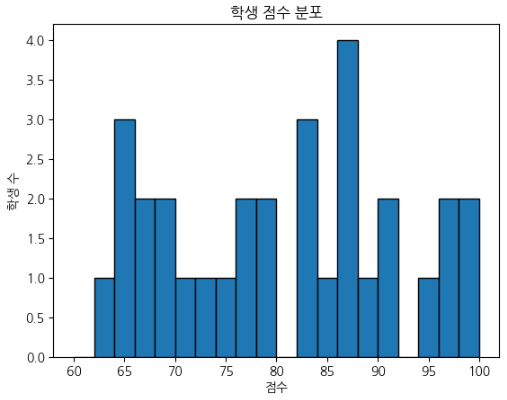

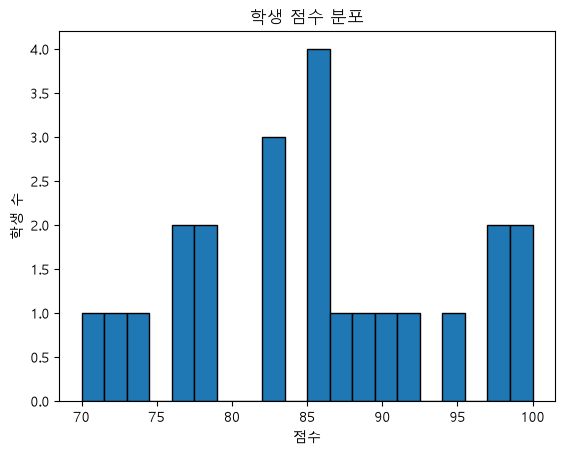

In [9]:
# code here
plt.title("학생 점수 분포")
plt.xlabel("점수")
plt.ylabel("학생 수")
plt.hist(df["점수"], edgecolor = "black", bins = 20, range= (70, 100))
plt.show()

### **Q6. 두 그룹의 히스토그램을 겹쳐서 비교하기**

성별 기준으로 나눠서 남학생과 여학생의 점수 히스토그램을 반투명하게 겹쳐 그린다.
- 범례를 통해 구분할 수 있도록 한다.


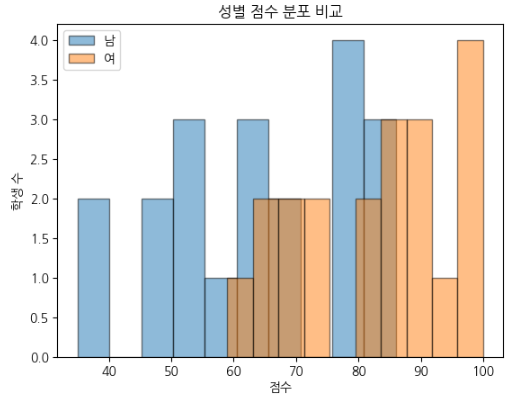

In [14]:
male = df[df["성별"] == "남"]
female = df[df["성별"] == "여"]

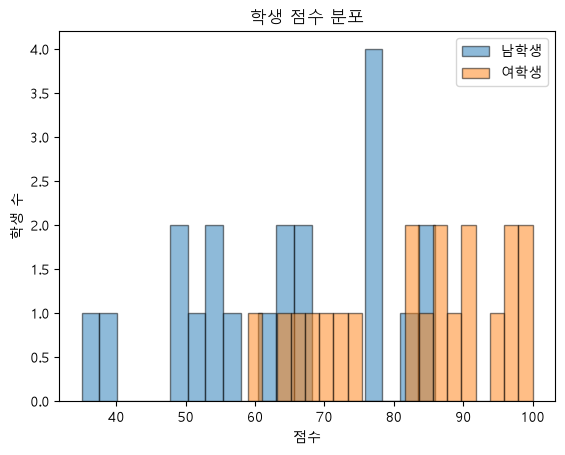

In [17]:
# code here
plt.title("학생 점수 분포")
plt.xlabel("점수")
plt.ylabel("학생 수")
plt.hist(male["점수"], edgecolor = "black", bins = 20, alpha = 0.5, label = "남학생")
plt.hist(female["점수"], edgecolor = "black", bins = 20, alpha = 0.5, label = "여학생")
plt.legend()
plt.show()

### **Q7. 새 열을 만들어서 그룹별로 비교하기**

- 점수가 70점 이상이면 1, 미만이면 0인 '합격여부' 열을 새로 만든다.
- 합격/불합격 두 그룹의 출석률 히스토그램을 겹쳐서 비교해보자.


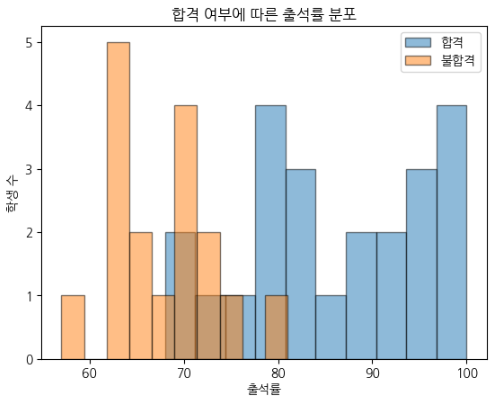

In [21]:
s = np.where(df["점수"] >= 70, 1, 0)
df["합격여부"] = s
s_s = df[df["합격여부"] == 1]
f_s = df[df["합격여부"] == 0]

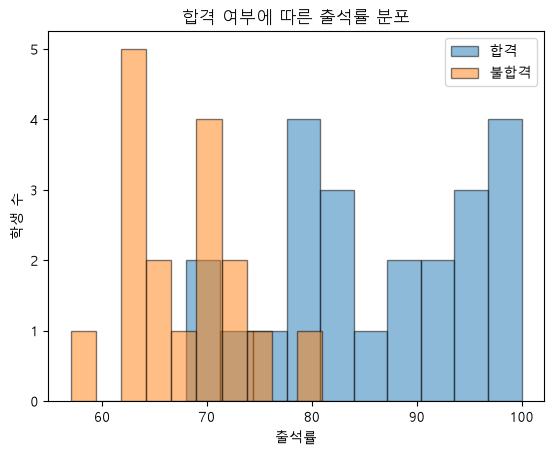

In [23]:
# code here
plt.title("합격 여부에 따른 출석률 분포")
plt.xlabel("출석률")
plt.ylabel("학생 수")
plt.hist(s_s["출석률"], edgecolor = "black", bins = 10, alpha = 0.5, label = "합격")
plt.hist(f_s["출석률"], edgecolor = "black", bins = 10, alpha = 0.5, label = "불합격")
plt.legend()
plt.show()